<a href="https://colab.research.google.com/github/dkalchenko01/Final-project-Time-Series/blob/main/01_eda_ets_snaive.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# EDA and first submission: ETS + seasonal naive

**Task.** Forecast hourly electricity generation for the next 48 hours and give a 95% prediction interval for every hour. Generation is nonnegative. The official benchmark repeats the last 24 observations twice.

**What this notebook does**

1. Checks the data and explores it (EDA).
2. Looks at transformations and a daily STL decomposition.
3. Retraces how the first model was chosen. This is a short, cleaned-up version of the search, not a log of every experiment.
4. Fits the chosen model, builds the intervals, and writes `submissions/submission_1_reproduced.csv`.

**First submitted model.** An equal combination of

- ETS (additive errors, damped additive trend, additive daily seasonality) fitted to a Box–Cox transformation of the **last 30 days**, and
- the seasonal naive forecast (last observed 24 hours, repeated twice),

with 95% intervals that are widened using the errors of earlier, already completed forecasts.

**How to read the validation numbers**

- Every historical forecast uses only data available before its origin.
- The backtest periods were reused while choosing the model, so the numbers are *retrospective evidence*, not an untouched final test.
- "Mean window RMSE" (average of the per-window RMSE values) and "pooled RMSE" (one RMSE over all hours) are different aggregates. They are labelled and are never mixed.
- No weather inputs, holidays, neural networks or public leaderboard results enter this model.

## 1. Setup and data

In [62]:
%pip install -q statsforecast==2.1.1 statsmodels

In [63]:
from pathlib import Path
from time import perf_counter
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import boxcox
from scipy.special import inv_boxcox
from statsforecast.models import AutoETS
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.tsa.seasonal import STL

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.figsize": (11, 3), "axes.grid": True, "grid.alpha": 0.25})
pd.set_option("display.width", 120, "display.precision", 3)

# Use the repository data folder, or upload both files in Colab.
DATA_DIR = Path("data") if Path("data/train.csv").exists() else Path(".")
NEEDED = ["train.csv", "weather_forecast.csv"]
if not all((DATA_DIR / name).exists() for name in NEEDED):
    from google.colab import files
    files.upload()
    DATA_DIR = Path(".")
data = pd.read_csv(DATA_DIR / "train.csv", parse_dates=["ds"])
weather_fc = pd.read_csv(DATA_DIR / "weather_forecast.csv", parse_dates=["ds"])

H = 48  # forecast horizon, hours
M = 24  # seasonal period, hours (one day)
y = data["y"].to_numpy(float)
FUTURE = weather_fc["ds"].reset_index(drop=True)
FEATURES = list(weather_fc.columns.drop("ds"))

### Data checks

We check chronological order, hourly spacing, duplicates, missing values, positivity of the target (Box–Cox needs it), and that the forecast timestamps continue right after the last training hour. The original observations are not modified.

In [64]:
assert data["ds"].is_monotonic_increasing and data["ds"].is_unique
assert data["ds"].diff().dropna().eq(pd.Timedelta(hours=1)).all()
assert np.isfinite(data.drop(columns="ds").to_numpy()).all()
assert (y > 0).all()
expected_future = pd.Series(
    pd.date_range(data["ds"].iloc[-1] + pd.Timedelta(hours=1), periods=H, freq="h"), name="ds"
)
assert FUTURE.equals(expected_future), "forecast dates do not follow the training data"

print("History :", data["ds"].iloc[0], "to", data["ds"].iloc[-1], f"({len(data)} hours)")
print("Forecast:", FUTURE.iloc[0], "to", FUTURE.iloc[-1])
display(data.head())
display(data.isna().sum().to_frame("missing").T)
display(data.describe().T)

History : 2023-01-01 01:00:00 to 2026-10-27 00:00:00 (33480 hours)
Forecast: 2026-10-27 01:00:00 to 2026-10-29 00:00:00


,ds,y,cloud_cover,temperature,wind_speed,pressure,humidity,daylight,air_density
0,2023-01-01 01:00:00,30.1,0.0,-7,1,765,96,0,1.338
1,2023-01-01 02:00:00,30.1,0.0,-7,1,765,96,0,1.338
2,2023-01-01 03:00:00,19.2,0.0,-7,1,765,96,0,1.338
3,2023-01-01 04:00:00,15.1,0.0,-7,1,765,96,0,1.338
4,2023-01-01 05:00:00,21.9,0.0,-8,1,765,95,0,1.343


,ds,y,cloud_cover,temperature,wind_speed,pressure,humidity,daylight,air_density
missing,0,0,0,0,0,0,0,0,0


,count,mean,min,25%,50%,75%,max,std
ds,33480,2024-11-28 12:30:00,2023-01-01 01:00:00,2023-12-15 18:45:00,2024-11-28 12:30:00,2025-11-12 06:15:00,2026-10-27 00:00:00,NaN
y,33480.0,315.755,0.7,94.5,220.6,356.2,3111.3,377.596
cloud_cover,33480.0,0.603,0.0,0.25,0.75,1.0,1.0,0.418
temperature,33480.0,12.225,-19.0,4.0,12.0,21.0,39.0,10.664
wind_speed,33480.0,3.727,0.0,2.0,3.0,5.0,14.0,2.326
pressure,33480.0,757.662,736.0,754.0,757.0,761.0,775.0,5.537
humidity,33480.0,71.699,7.0,56.0,77.0,89.0,100.0,21.176
daylight,33480.0,0.475,0.0,0.0,0.0,1.0,1.0,0.499
air_density,33480.0,1.238,1.124,1.198,1.235,1.275,1.41,0.05


## 2. Exploratory data analysis

Full history and recent levels, monthly and daily profiles, distribution and variability, autocorrelation, and the weather variables.

In [65]:
eda = data.copy()
eda["year"] = eda["ds"].dt.year
eda["month"] = eda["ds"].dt.month
eda["hour"] = eda["ds"].dt.hour

recent = eda.tail(90 * M).copy()  # last 90 days, used for most "recent behaviour" plots

print("Recent window:", recent["ds"].min(), "to", recent["ds"].max())
display(eda.groupby("year")["y"].agg(["count", "mean", "median", "std", "max"]))

Recent window: 2026-07-29 01:00:00 to 2026-10-27 00:00:00


,count,mean,median,std,max
year,,,,,
2023,8759,170.776,154.8,122.901,604.2
2024,8784,183.856,165.8,127.017,654.9
2025,8760,291.470,261.7,220.432,1324.8
2026,7177,683.766,450.7,620.142,3111.3


### 2.1 Level over time

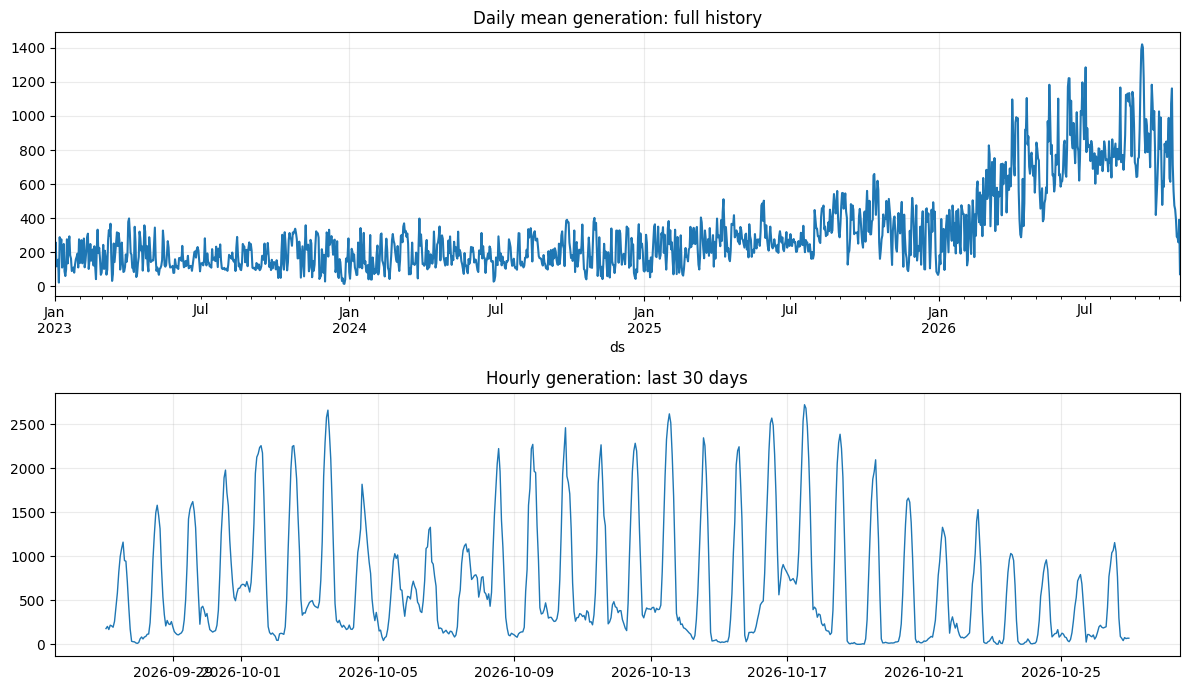

In [66]:
fig, axes = plt.subplots(2, 1, figsize=(12, 7))

eda.set_index("ds")["y"].resample("D").mean().plot(ax=axes[0])
axes[0].set_title("Daily mean generation: full history")

last_month = eda.tail(30 * M)
axes[1].plot(last_month["ds"], last_month["y"], linewidth=1)
axes[1].set_title("Hourly generation: last 30 days")

plt.tight_layout()
plt.show()

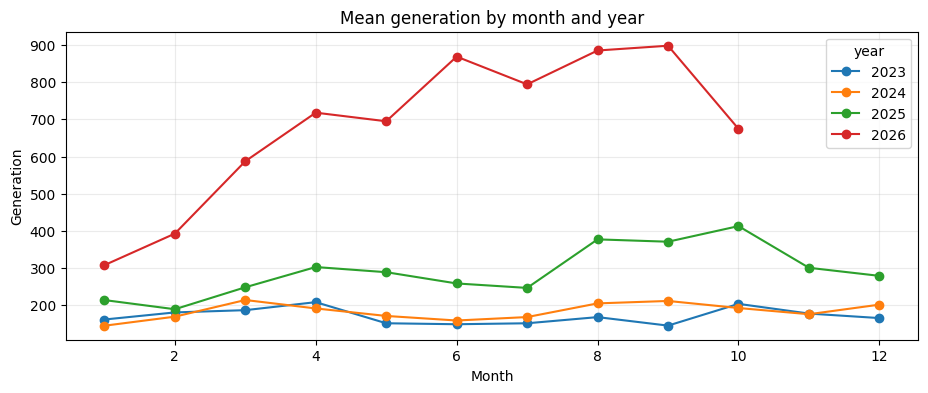

In [67]:
monthly = eda.groupby(["year", "month"])["y"].mean().unstack("year")
monthly.plot(marker="o", figsize=(11, 4))
plt.title("Mean generation by month and year")
plt.xlabel("Month")
plt.ylabel("Generation")
plt.show()

### 2.2 Daily profile, distribution and variability

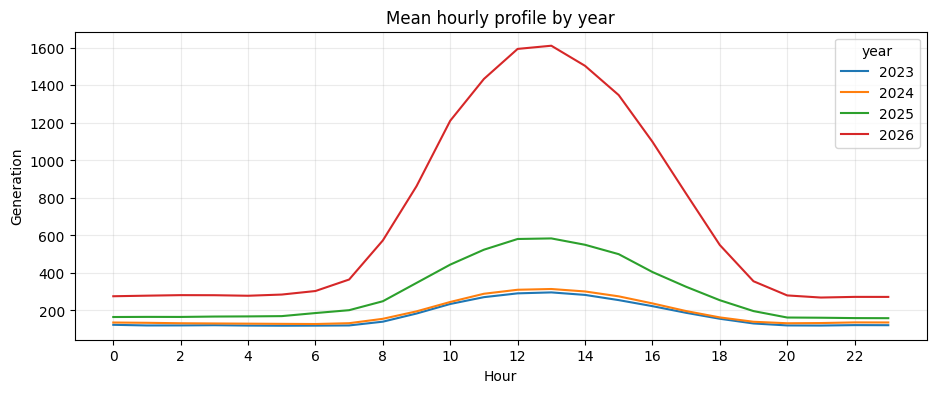

In [68]:
profiles = eda.groupby(["year", "hour"])["y"].mean().unstack("year")
profiles.plot(figsize=(11, 4))
plt.title("Mean hourly profile by year")
plt.xlabel("Hour")
plt.ylabel("Generation")
plt.xticks(range(0, 24, 2))
plt.show()

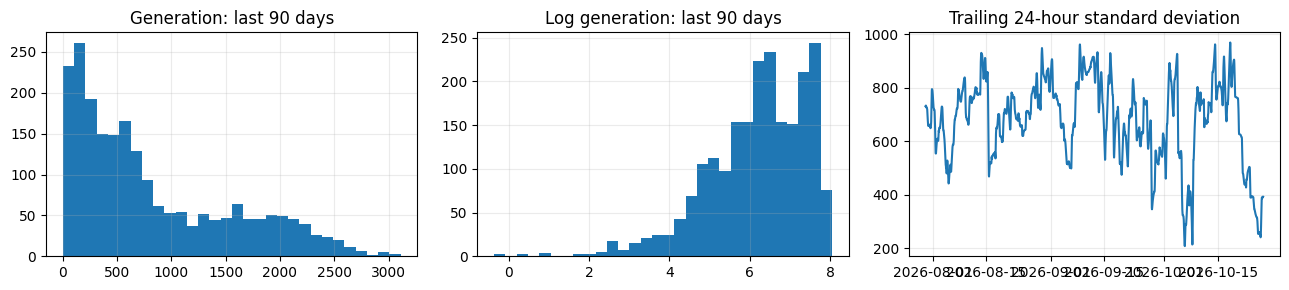

In [69]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3))
axes[0].hist(recent["y"], bins=30)
axes[0].set_title("Generation: last 90 days")
axes[1].hist(np.log(recent["y"]), bins=30)
axes[1].set_title("Log generation: last 90 days")
axes[2].plot(recent["ds"], recent["y"].rolling(M).std())
axes[2].set_title("Trailing 24-hour standard deviation")
plt.tight_layout()
plt.show()

The rolling standard deviation includes the daily cycle. A lower value means less variation within a day, not necessarily a smaller forecast error.

### 2.3 Autocorrelation

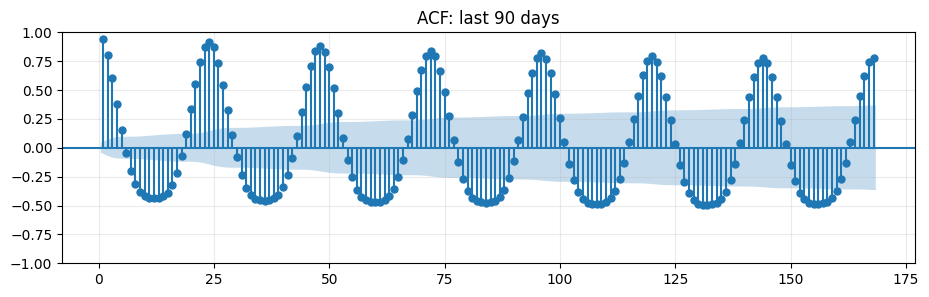

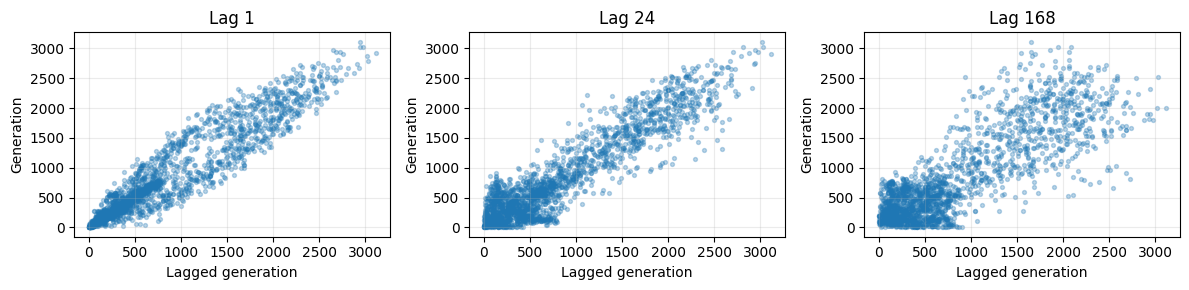

In [70]:
plot_acf(recent["y"], lags=7 * M, zero=False)
plt.title("ACF: last 90 days")
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(12, 3))
for ax, lag in zip(axes, [1, M, 7 * M]):
    ax.scatter(recent["y"].shift(lag), recent["y"], s=8, alpha=0.3)
    ax.set_title(f"Lag {lag}")
    ax.set_xlabel("Lagged generation")
    ax.set_ylabel("Generation")
plt.tight_layout()
plt.show()

### 2.4 Weather variables

Observed weather versus generation and how the supplied forecast compares with what we have seen recently

In [71]:
correlations = pd.DataFrame({
    "full_history": eda[["y"] + FEATURES].corr()["y"],
    "last_90_days": recent[["y"] + FEATURES].corr()["y"],
}).drop(index="y")
display(correlations.sort_values("last_90_days", ascending=False))

,full_history,last_90_days
daylight,0.395,0.721
wind_speed,0.303,0.561
temperature,0.280,0.506
cloud_cover,0.162,0.151
pressure,-0.025,0.050
air_density,-0.260,-0.455
humidity,-0.380,-0.597


In [72]:
day_night = recent.groupby("daylight")["y"].agg(
    ["count", "mean", "median", "std"]
)
day_night.index = day_night.index.map({0: "Night", 1: "Daylight"})
display(day_night.round(1))

,count,mean,median,std
daylight,,,,
Night,1093,308.4,260.3,221.9
Daylight,1067,1353.4,1337.1,678.2


Correlations with observed weather and generation during daylight and night.

### EDA Findings

- The level changes a lot between years and also over shorter periods. So I focus on recent data and compare training windows of 30, 60 and 90 days.
- There is a strong daily pattern: generation rises during the day and falls at night. I will use a seasonal period of 24 hours.
- In the last 90 days, average generation is about 1,353 during daylight and 308 at night. Daytime values also vary more.
- The distribution is right-skewed, with many small values and some large peaks. I will check whether a transformation helps model this variation.
- The ACF shows strong dependence between nearby hours and at daily lags. I do not see clear evidence for a separate weekly pattern.
- Weather may explain some variation, but these plots do not show whether it improves forecasts. The first model will use generation history only.

## 3. Transformations and decomposition

Everything in this section uses only the training part, with the last 48 hours held out. In every forecasting experiment later, the Box–Cox parameter is re-estimated inside each training window.

Box–Cox lambda: 0.197


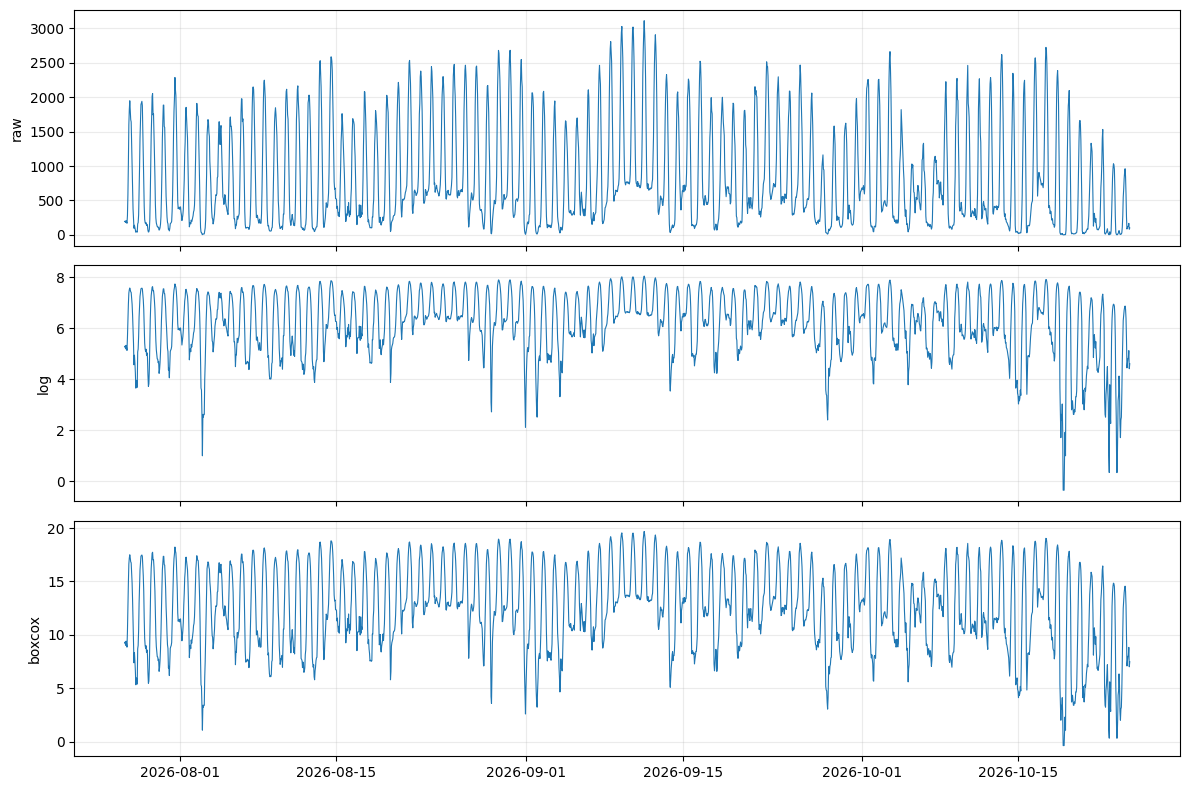

In [73]:
train_y = y[:-H]
train_dates = data["ds"].iloc[:-H].to_numpy()

train_log = np.log(train_y)
train_boxcox, BOXCOX_LAMBDA = boxcox(train_y)
print("Box–Cox lambda:", round(BOXCOX_LAMBDA, 3))

transformed = pd.DataFrame(
    {"raw": train_y, "log": train_log, "boxcox": train_boxcox}, index=pd.DatetimeIndex(train_dates, name="ds")
)

fig, axes = plt.subplots(3, 1, figsize=(12, 8), sharex=True)
for ax, column in zip(axes, ["raw", "log", "boxcox"]):
    ax.plot(transformed[column].tail(90 * M), linewidth=0.8)
    ax.set_ylabel(column)
plt.tight_layout()
plt.show()

The daily swing grows with the level on the original scale. Log and Box–Cox compress the large peaks, but log also makes the near-zero values more prominent. I keep Box–Cox as a candidate for additive ETS and compare it with the original scale in validation.

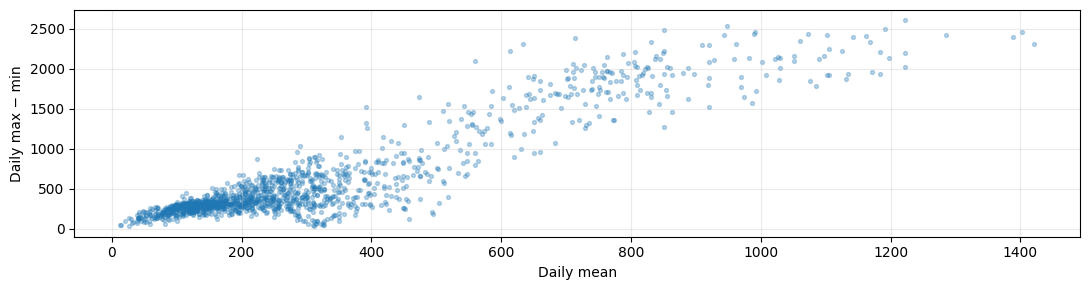

In [74]:
daily = transformed["raw"].resample("D").agg(count="count", level="mean", low="min", high="max", std="std")
daily = daily[daily["count"] == M].copy()
daily["swing"] = daily["high"] - daily["low"]

plt.scatter(daily["level"], daily["swing"], s=8, alpha=0.3)
plt.xlabel("Daily mean")
plt.ylabel("Daily max − min")
plt.tight_layout()
plt.show()

Days with higher average generation also have larger daily swings. This supports trying Box–Cox before fitting an additive seasonal ETS model.

### Daily STL decomposition: raw versus Box–Cox

STL with period 24 on the last 90 training days. This is a *description* of the series; it says nothing yet about forecast accuracy.

Fit on 90 days; plot only the last 14 days so the daily components remain readable.

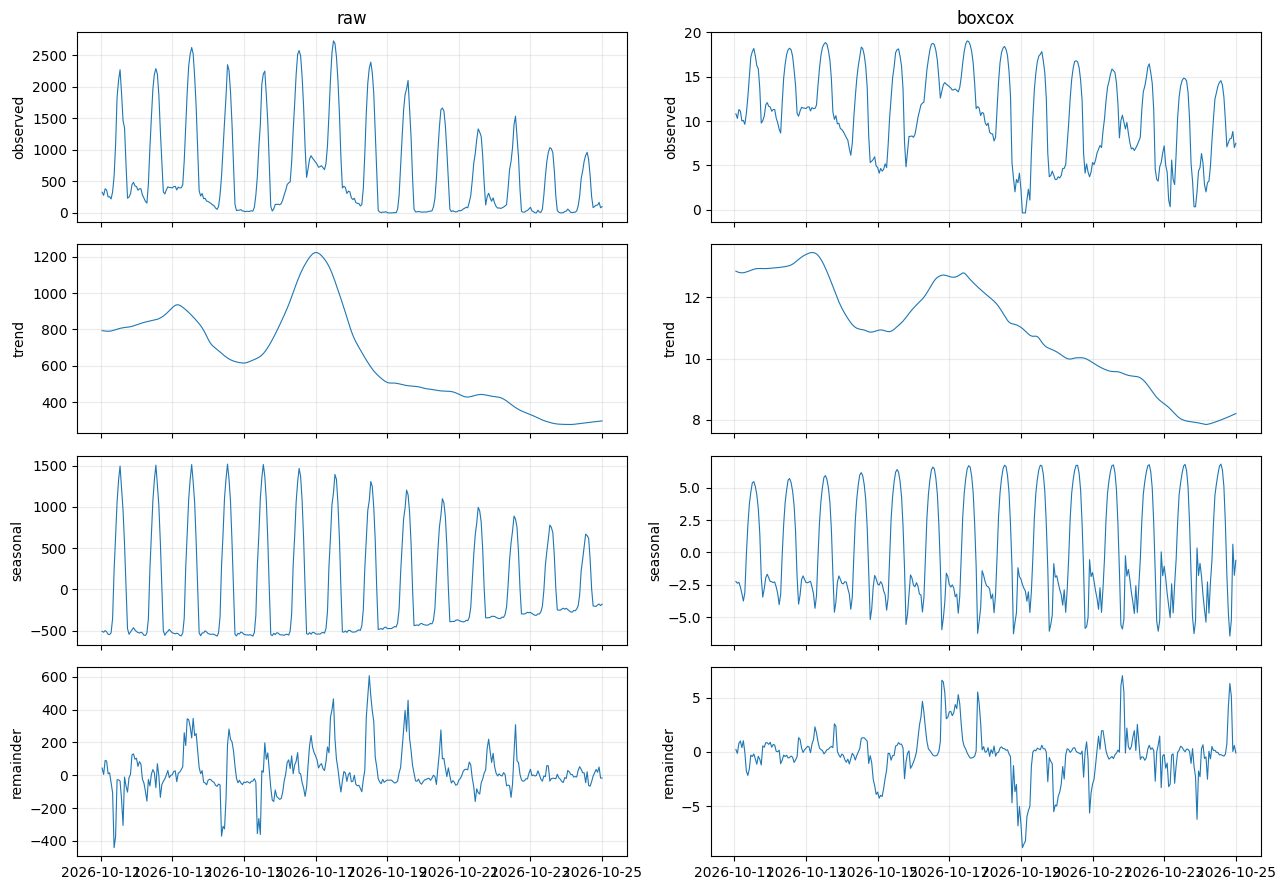

In [75]:
decomp = transformed[["raw", "boxcox"]].tail(90 * M)
stl = {col: STL(decomp[col], period=M, seasonal=13, robust=True).fit() for col in ["raw", "boxcox"]}

fig, axes = plt.subplots(4, 2, figsize=(13, 9), sharex=True)
for j, column in enumerate(["raw", "boxcox"]):
    fit = stl[column]
    parts = [decomp[column], fit.trend, fit.seasonal, fit.resid]
    for ax, values, label in zip(axes[:, j], parts, ["observed", "trend", "seasonal", "remainder"]):
        ax.plot(decomp.index[-14*M:], np.asarray(values)[-14*M:], linewidth=0.8)
        ax.set_ylabel(label)
    axes[0, j].set_title(column)
plt.tight_layout()
plt.show()

### Reading the decomposition
**Trend.** The level peaks around 17 October, then falls. It changes over days rather than following a steady trend, so I use recent training data.

**Seasonality.** Peaks repeat every 24 hours. Their amplitude changes with the level on the raw scale and is more stable after Box–Cox.

**Remainder.** Runs of positive and negative deviations remain, with several large spikes. I check their dependence with the ACF.

This supports comparing raw and Box–Cox ETS with daily seasonality.

,trend_strength,seasonal_strength
raw,0.678,0.946
boxcox,0.526,0.828


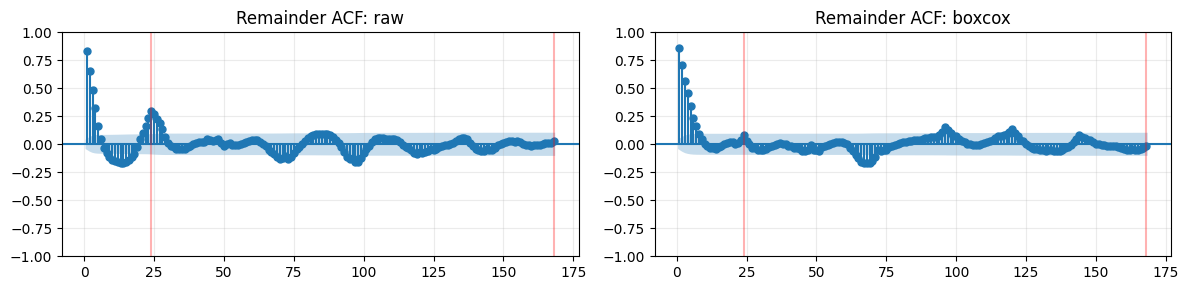

In [76]:
def component_strengths(fit):
    # Strength of trend / seasonality, 0 = none, 1 = perfect (Hyndman & Athanasopoulos).
    remainder = np.var(fit.resid)
    return {
        "trend_strength": max(0, 1 - remainder / np.var(fit.trend + fit.resid)),
        "seasonal_strength": max(0, 1 - remainder / np.var(fit.seasonal + fit.resid)),
    }

display(pd.DataFrame({col: component_strengths(fit) for col, fit in stl.items()}).T)

fig, axes = plt.subplots(1, 2, figsize=(12, 3))
for ax, column in zip(axes, ["raw", "boxcox"]):
    plot_acf(stl[column].resid, lags=7 * M, zero=False, ax=ax)
    ax.axvline(M, color="red", alpha=0.3)       # one day
    ax.axvline(7 * M, color="red", alpha=0.3)   # one week
    ax.set_title(f"Remainder ACF: {column}")
plt.tight_layout()
plt.show()

Daily seasonality is strong: 0.946 raw and 0.828 after Box–Cox.

→ Box–Cox reduces the remainder ACF peak at lag 24, but strong short-lag dependence remains

→ Lower component strengths after transformation do not imply worse forecasts. I compare both scales in validation

## 4. Building blocks: metrics, benchmark, ETS, combination, calibration

All forecasts are a tuple `(point, lower_95, upper_95)` of three arrays of length 48.

- **RMSE** and **MAPE** judge the point forecast. MAPE is very sensitive to small actual values, which are common at night.
- **Winkler** judges the interval: its width plus a penalty of 40 times the distance by which the actual value falls outside it.
- **Coverage** is the share of actual values inside the interval, and the target is 0.95.

In [77]:
# Metrics
def score(actual, prediction):
    point, lower, upper = prediction
    miss = np.maximum(lower - actual, 0) + np.maximum(actual - upper, 0)
    return {
        "RMSE": np.sqrt(np.mean((actual - point) ** 2)),
        "MAPE": 100 * np.mean(np.abs(actual - point) / actual),
        "Winkler": np.mean(upper - lower + 40 * miss),  # 40 = 2 / alpha for a 95% interval
        "coverage": np.mean((actual >= lower) & (actual <= upper)),
        "width": np.mean(upper - lower),
    }


PARTS = {"all": slice(None), "day 1": slice(0, M), "day 2": slice(M, H)}
METRICS = ["RMSE", "MAPE", "Winkler", "coverage", "width"]


def add_scores(rows, key, actual, prediction):
    """Append one row per part (all hours, day 1, day 2) to `rows`."""
    for part, s in PARTS.items():
        rows.append({**key, "part": part, **score(actual[s], tuple(a[s] for a in prediction))})


def summarize(scores, part="all", by="model"):
    """Mean over windows of each metric. This is the *mean window* aggregate."""
    return scores[scores["part"] == part].groupby(by)[METRICS].mean()


# Benchmark: official seasonal naive
def snaive(history, h=H, m=M):
    """Repeat the last season. The interval is y_hat ± 1.96 * sigma * sqrt(k + 1), where k is
    the number of full days into the horizon and sigma comes from seasonal differences."""
    history = np.asarray(history, float)
    point = np.resize(history[-m:], h)
    sigma = np.std(history[m:] - history[:-m], ddof=1)
    half = 1.96 * sigma * np.sqrt(1 + np.arange(h) // m)
    return point, np.maximum(point - half, 0), point + half

In [78]:
# Target transformations
def transform_target(values, kind="raw"):
    values = np.asarray(values, float)
    if kind == "raw":
        return values.copy(), None
    if not (values > 0).all():
        raise ValueError("Log and Box–Cox need positive values")
    if kind == "log":
        return np.log(values), None
    if kind == "boxcox":
        return boxcox(values)  # returns (transformed values, lambda)
    raise ValueError("kind must be raw, log or boxcox")


def inverse_target(values, kind="raw", lam=None):
    values = np.asarray(values, float)
    if kind == "raw":
        return values.copy()
    if kind == "log":
        return np.exp(values)
    return inv_boxcox(values, lam)


def to_original_scale(out, kind, lam, bias_adjust=False):
    """Back-transform a model forecast (columns mean, lo-95, hi-95) to the original scale.

    Without bias adjustment the back-transformed centre is a median-type forecast.
    With bias_adjust=True an approximate mean correction is applied after Box–Cox.
    """
    center, lo, hi = (np.asarray(out[k], float) for k in ["mean", "lo-95", "hi-95"])
    point = inverse_target(center, kind, lam)
    if kind == "boxcox":
        if bias_adjust:
            sigma = (hi - lo) / (2 * 1.96)
            if abs(lam) < 1e-6:
                point = np.exp(center + sigma ** 2 / 2)
            else:
                base = 1 + lam * center
                if np.any(base <= 0):
                    raise ValueError("Box–Cox point forecast outside the inverse domain")
                point = point * (1 + (1 - lam) * sigma ** 2 / (2 * base ** 2))
        # Generation is nonnegative: cap the transformed lower bound at the support of the inverse.
        lo = np.maximum(1 + lam * lo, 0) ** (1 / lam) if lam > 0 else inverse_target(lo, kind, lam)
        hi = inverse_target(hi, kind, lam)
    point = np.maximum(point, 0)
    lower = np.minimum(np.maximum(lo, 0), point)
    upper = np.maximum(hi, point)
    assert all(a.shape == (H,) and np.isfinite(a).all() for a in (point, lower, upper))
    return point, lower, upper


# Ets
def ets_forecast(history, kind="boxcox", lookback=None, bias_adjust=False):
    """ETS with additive errors, damped additive trend and additive daily seasonality.
    `lookback` is the number of most recent hours to fit on (None = all history).
    The Box–Cox lambda is re-estimated on exactly the hours the model is fitted on."""
    history = np.asarray(history, float)
    if lookback is not None:
        history = history[-lookback:]
    z, lam = transform_target(history, kind)
    out = AutoETS(season_length=M, model="AAA", damped=True).fit(y=z).predict(h=H, level=[95])
    return to_original_scale(out, kind, lam, bias_adjust)

In [79]:
# Combination with seasonal naive
def combine(w, ets, naive, bounds="avg"):
    """Weighted combination: w * ETS + (1 − w) * seasonal naive.
    bounds="avg" averages the component bounds with the same weights (a practical recipe, not an
    exact mixture quantile); bounds="ets" keeps the ETS bounds only."""
    e_point, e_lo, e_hi = ets
    n_point, n_lo, n_hi = naive
    point = w * e_point + (1 - w) * n_point
    if bounds == "avg":
        lower, upper = w * e_lo + (1 - w) * n_lo, w * e_hi + (1 - w) * n_hi
    else:
        lower, upper = e_lo, e_hi
    return point, np.minimum(lower, point), np.maximum(upper, point)  # keep the point inside


# Empirical interval calibration
def calibrate(prediction, past_predictions, series=y, alpha=0.05):
    """Widen the interval using misses of earlier, completed forecasts.

    For every past forecast we measure how far each actual value fell outside its interval,
    divided by that interval's half-width. The (1 − alpha) empirical quantile of these
    normalised misses, taken separately for day 1 and day 2, is added to both bounds in units
    of the new interval's half-width.

    The miss is never negative, so this recipe can only widen an interval, never shrink it.
    It does not guarantee 95% coverage in a dependent, changing series.
    """
    point, lower, upper = (a.copy() for a in prediction)
    scale = np.maximum((upper - lower) / 2, 1)
    for part in [slice(0, M), slice(M, H)]:
        errors = []
        for end, (_, lo, hi) in past_predictions.items():
            actual = series[end:end + H]
            miss = np.maximum.reduce([lo - actual, actual - hi, np.zeros(H)])
            errors.extend((miss / np.maximum((hi - lo) / 2, 1))[part])
        errors = np.sort(errors)
        rank = min(len(errors), int(np.ceil((len(errors) + 1) * (1 - alpha))))
        q = errors[rank - 1]
        lower[part] = np.maximum(lower[part] - q * scale[part], 0)
        upper[part] += q * scale[part]
    return point, lower, upper

## 5. Reconstruction of the model search

### Step 1. ETS candidates versus the benchmark

First, I compare raw and Box–Cox ETS using the last 90 days, against seasonal naive. Later, I compare training windows of 30, 60 and 90 days.

In [80]:
SEARCH_ORIGINS = [len(data) - k * H for k in (4, 3, 2)]
CONFIRM_ORIGIN = len(data) - H

for end in SEARCH_ORIGINS:
    print("search      :", data["ds"].iloc[end], "to", data["ds"].iloc[end + H - 1])
print("confirmation:", data["ds"].iloc[CONFIRM_ORIGIN], "to", data["ds"].iloc[-1])

EARLY_CANDIDATES = {
    "ETS raw 90d": ("raw", 90 * M),
    "ETS Box-Cox 90d": ("boxcox", 90 * M),
}

rows = []
for window, end in enumerate(SEARCH_ORIGINS, start=1):
    actual = y[end:end + H]
    add_scores(rows, {"window": window, "model": "seasonal naive"}, actual, snaive(y[:end]))
    for name, (kind, lookback) in EARLY_CANDIDATES.items():
        started = perf_counter()
        prediction = ets_forecast(y[:end], kind, lookback, bias_adjust=True)
        add_scores(rows, {"window": window, "model": name}, actual, prediction)
        print(f"window {window}  {name:<18} {perf_counter() - started:4.1f} s", flush=True)

early_scores = pd.DataFrame(rows)

for part in ["all", "day 2"]:
    table = summarize(early_scores, part)
    table["RMSE / benchmark"] = table["RMSE"] / table.loc["seasonal naive", "RMSE"]
    print(f"\nMean over the 3 search windows, {part}")
    display(table.sort_values("RMSE"))

search      : 2026-10-19 01:00:00 to 2026-10-21 00:00:00
search      : 2026-10-21 01:00:00 to 2026-10-23 00:00:00
search      : 2026-10-23 01:00:00 to 2026-10-25 00:00:00
confirmation: 2026-10-25 01:00:00 to 2026-10-27 00:00:00
window 1  ETS raw 90d         0.5 s
window 1  ETS Box-Cox 90d     0.7 s
window 2  ETS raw 90d         0.8 s
window 2  ETS Box-Cox 90d     1.0 s
window 3  ETS raw 90d         1.1 s
window 3  ETS Box-Cox 90d     2.3 s

Mean over the 3 search windows, all


,RMSE,MAPE,Winkler,coverage,width,RMSE / benchmark
model,,,,,,
ETS Box-Cox 90d,193.030,616.589,798.628,0.840,651.375,0.870
seasonal naive,221.898,872.396,1228.808,0.861,579.428,1.000
ETS raw 90d,268.722,718.336,1551.360,0.875,617.942,1.211



Mean over the 3 search windows, day 2


,RMSE,MAPE,Winkler,coverage,width,RMSE / benchmark
model,,,,,,
ETS Box-Cox 90d,170.600,136.512,676.146,0.944,672.359,0.687
seasonal naive,248.345,156.378,1476.951,0.861,670.488,1.000
ETS raw 90d,292.035,156.127,1700.901,0.861,637.882,1.176


In [81]:
# Confirmation window: only the leading candidate, compared with the benchmark.
actual = y[CONFIRM_ORIGIN:CONFIRM_ORIGIN + H]
display(pd.DataFrame({
    "seasonal naive": score(actual, snaive(y[:CONFIRM_ORIGIN])),
    "ETS Box-Cox 90d": score(actual, ets_forecast(y[:CONFIRM_ORIGIN], "boxcox", 90 * M, bias_adjust=True)),
}).T[["RMSE", "MAPE", "Winkler", "coverage"]])

,RMSE,MAPE,Winkler,coverage
seasonal naive,120.404,51.088,568.464,1.000
ETS Box-Cox 90d,197.158,45.330,711.599,0.958


ETS Box–Cox has the lowest average RMSE on the three search windows (193 vs 222 for seasonal naive), but loses on the confirmation window (197 vs 120). Its performance varies between windows, so I next test a combination with seasonal naive.

### Step 2. Other models tried

I also tested STL + ETS, regression with ARIMA errors, and weather-based boosting. These settings did not give a convincing improvement in the initial comparisons, so I continue with ETS and seasonal naive as candidates.

### Step 3. Mixing ETS with the seasonal naive

ETS was better than the benchmark on average in the search windows but lost on the confirmation window. The two methods make different kinds of mistakes: the naive repeats yesterday exactly, while ETS smooths and follows the level. An equal mix is a standard and cheap way to hedge.

From here on, we use **28 non-overlapping 48-hour windows** (about 56 days) ending at the end of the data. Window `i` is forecast from the data before its origin only. The first 8 windows will later serve only as warm-up for the calibration in Step 4, so every comparison from Step 4 on is scored on the other 20.

In this step all 28 windows are scored with uncalibrated forecasts.

In [82]:
N_ORIGINS, WARMUP, CAL_WINDOW = 28, 8, 12
ORIGINS = [len(data) - k * H for k in range(N_ORIGINS, 0, -1)]
SCORED = ORIGINS[WARMUP:]  # windows scored with calibrated intervals

print("All windows   :", data["ds"].iloc[ORIGINS[0]], "to", data["ds"].iloc[-1])
print("Scored windows:", data["ds"].iloc[SCORED[0]], "to", data["ds"].iloc[-1], f"({len(SCORED)} windows)")

# Forecasts depend only on (origin, history length, back-transform), so we cache them.
_ets_cache, _naive_cache = {}, {}


def naive_at(end):
    if end not in _naive_cache:
        _naive_cache[end] = snaive(y[:end])
    return _naive_cache[end]


def ets_at(end, days, bias_adjust):
    key = (end, days, bias_adjust)
    if key not in _ets_cache:
        _ets_cache[key] = ets_forecast(y[:end], "boxcox", days * M, bias_adjust)
    return _ets_cache[key]


def combo_at(end, days, bias_adjust, w=0.5, bounds="avg"):
    return combine(w, ets_at(end, days, bias_adjust), naive_at(end), bounds)


def evaluate(predictions, ends):
    """`predictions` maps a model name to {origin: forecast}. Returns one row per origin/model/part."""
    rows = []
    for name, by_origin in predictions.items():
        for end in ends:
            add_scores(rows, {"origin": end, "model": name}, y[end:end + H], by_origin[end])
    return pd.DataFrame(rows)


started = perf_counter()
for end in ORIGINS:
    ets_at(end, 90, True)
print(f"ETS Box-Cox 90d fitted on {N_ORIGINS} windows in {perf_counter() - started:.0f} s")

step3 = evaluate({
    "seasonal naive": {e: naive_at(e) for e in ORIGINS},
    "ETS Box-Cox 90d": {e: ets_at(e, 90, True) for e in ORIGINS},
    "combo w=0.25 (ETS bounds)": {e: combo_at(e, 90, True, 0.25, "ets") for e in ORIGINS},
    "combo w=0.50 (ETS bounds)": {e: combo_at(e, 90, True, 0.50, "ets") for e in ORIGINS},
    "combo w=0.75 (ETS bounds)": {e: combo_at(e, 90, True, 0.75, "ets") for e in ORIGINS},
    "combo w=0.50 (averaged bounds)": {e: combo_at(e, 90, True, 0.50, "avg") for e in ORIGINS},
}, ORIGINS)

for part in ["all", "day 2"]:
    table = summarize(step3, part)
    table["RMSE / benchmark"] = table["RMSE"] / table.loc["seasonal naive", "RMSE"]
    print(f"\nUncalibrated, mean over {N_ORIGINS} windows, {part}")
    display(table.sort_values("RMSE"))

All windows   : 2026-09-01 01:00:00 to 2026-10-27 00:00:00
Scored windows: 2026-09-17 01:00:00 to 2026-10-27 00:00:00 (20 windows)
ETS Box-Cox 90d fitted on 28 windows in 22 s

Uncalibrated, mean over 28 windows, all


,RMSE,MAPE,Winkler,coverage,width,RMSE / benchmark
model,,,,,,
combo w=0.50 (averaged bounds),275.367,169.907,1392.647,0.857,859.405,0.915
combo w=0.50 (ETS bounds),275.367,169.907,1570.837,0.854,1043.261,0.915
combo w=0.75 (ETS bounds),280.538,160.325,1570.831,0.854,1043.255,0.932
combo w=0.25 (ETS bounds),283.079,180.797,1563.482,0.854,1043.909,0.940
ETS Box-Cox 90d,296.966,151.997,1570.831,0.854,1043.255,0.987
seasonal naive,301.014,194.179,2281.547,0.760,675.556,1.000



Uncalibrated, mean over 28 windows, day 2


,RMSE,MAPE,Winkler,coverage,width,RMSE / benchmark
model,,,,,,
combo w=0.50 (averaged bounds),290.242,132.636,1453.449,0.879,925.925,0.922
combo w=0.50 (ETS bounds),290.242,132.636,1795.827,0.836,1070.783,0.922
combo w=0.75 (ETS bounds),294.611,126.553,1795.827,0.836,1070.783,0.936
combo w=0.25 (ETS bounds),298.220,140.326,1780.399,0.836,1071.362,0.947
ETS Box-Cox 90d,313.719,122.254,1795.827,0.836,1070.783,0.996
seasonal naive,314.836,150.597,2138.755,0.815,781.066,1.000


The 50/50 combination has the lowest RMSE among the tested weights: 275 versus 301 for seasonal naive, an improvement of about 8.5%.

Averaging the bounds also gives a lower Winkler score than using ETS bounds alone (1393 vs 1571). However, coverage is only 85.7%, below the 95% target.

I keep equal weights and averaged bounds, then calibrate the intervals using earlier forecast errors.

### Step 4. Adjusting intervals and the point forecast

The intervals covered too few actual values. I widen them using errors from up to 12 earlier forecasts, separately for day 1 and day 2. The first 8 windows collect errors; the next 20 are scored.

I also compare two ways to return the Box–Cox forecast to the original scale: without a bias adjustment (median-type) and with an adjustment (approximate mean). I check which gives lower forecast errors.

In [83]:
def calibrated(raw):
    """Calibrate each scored window with the (up to) 12 windows completed just before it.
    `raw` maps origin -> uncalibrated forecast."""
    out = {}
    for i, end in enumerate(ORIGINS):
        if i < WARMUP:
            continue
        previous = {o: raw[o] for o in ORIGINS[max(0, i - CAL_WINDOW):i]}
        out[end] = calibrate(raw[end], previous)
    return out


for end in ORIGINS:
    ets_at(end, 90, False)  # median-type version of the same ETS model

raw_mean = {e: combo_at(e, 90, True) for e in ORIGINS}
raw_median = {e: combo_at(e, 90, False) for e in ORIGINS}

step4 = evaluate({
    "mean, not calibrated": raw_mean,
    "mean, calibrated": calibrated(raw_mean),
    "median, calibrated": calibrated(raw_median),
}, SCORED)

for part in ["all", "day 2"]:
    print(f"\nMean over the {len(SCORED)} scored windows, {part}")
    display(summarize(step4, part))


Mean over the 20 scored windows, all


,RMSE,MAPE,Winkler,coverage,width
model,,,,,
"mean, calibrated",287.293,215.110,1286.650,0.935,1053.443
"mean, not calibrated",287.293,215.110,1466.129,0.843,837.651
"median, calibrated",284.354,204.574,1286.650,0.935,1053.443



Mean over the 20 scored windows, day 2


,RMSE,MAPE,Winkler,coverage,width
model,,,,,
"mean, calibrated",295.245,164.143,1416.752,0.925,1070.831
"mean, not calibrated",295.245,164.143,1540.733,0.871,903.605
"median, calibrated",290.519,157.701,1416.752,0.925,1070.831


Calibration raises coverage from 84.3% to 93.5% and lowers Winkler from 1466 to 1287, despite wider intervals.

Without the mean bias adjustment, RMSE falls from 287 to 284 and MAPE from 215 to 205. The interval metrics stay unchanged.

I keep the median-type forecast and calibrated intervals.

### Step 5. How much ETS history: 30, 60 or 90 days?

The same combined model with ETS fitted on the last 30, 60 or 90 days, all calibrated the same way, on the same 20 scored windows. The seasonal naive with its native interval is the benchmark.

In [84]:
started = perf_counter()
raw_by_days = {}
for days in (30, 60, 90):
    raw_by_days[days] = {e: combo_at(e, days, False) for e in ORIGINS}
    print(f"{days} days done, {perf_counter() - started:.0f} s elapsed", flush=True)

lookback_predictions = {f"combo, ETS {d}d": calibrated(raw) for d, raw in raw_by_days.items()}
lookback_predictions["seasonal naive"] = {e: naive_at(e) for e in SCORED}
step5 = evaluate(lookback_predictions, SCORED)

for part in ["all", "day 2"]:
    print(f"\nMean over the {len(SCORED)} scored windows, {part}")
    display(summarize(step5, part))

# Pooled RMSE is a different aggregate: one RMSE over all hours of all scored windows.
pooled = {name: np.sqrt(np.mean(np.concatenate([(y[e:e + H] - p[e][0]) ** 2 for e in SCORED])))
          for name, p in lookback_predictions.items()}
print("\nPooled RMSE over all scored hours (not comparable with the mean-window column):")
display(pd.Series(pooled, name="pooled RMSE").to_frame().T)

# How consistent is the difference between 30 and 90 days?
rmse_by_window = step5[step5["part"] == "all"].pivot(index="origin", columns="model", values="RMSE")
wins = int((rmse_by_window["combo, ETS 30d"] < rmse_by_window["combo, ETS 90d"]).sum())
print(f"30d has a lower RMSE than 90d in {wins} of {len(SCORED)} windows")

30 days done, 6 s elapsed
60 days done, 15 s elapsed
90 days done, 15 s elapsed

Mean over the 20 scored windows, all


,RMSE,MAPE,Winkler,coverage,width
model,,,,,
"combo, ETS 30d",274.930,226.735,1307.860,0.950,1094.920
"combo, ETS 60d",279.724,205.488,1307.418,0.945,1061.690
"combo, ETS 90d",284.354,204.574,1286.650,0.935,1053.443
seasonal naive,308.922,249.001,2396.705,0.749,671.364



Mean over the 20 scored windows, day 2


,RMSE,MAPE,Winkler,coverage,width
model,,,,,
"combo, ETS 30d",280.689,155.302,1401.586,0.948,1094.341
"combo, ETS 60d",285.839,156.369,1435.887,0.935,1076.949
"combo, ETS 90d",290.519,157.701,1416.752,0.925,1070.831
seasonal naive,313.940,187.639,2095.180,0.823,775.402



Pooled RMSE over all scored hours (not comparable with the mean-window column):


,"combo, ETS 30d","combo, ETS 60d","combo, ETS 90d",seasonal naive
pooled RMSE,292.316,297.796,301.813,322.016


30d has a lower RMSE than 90d in 14 of 20 windows


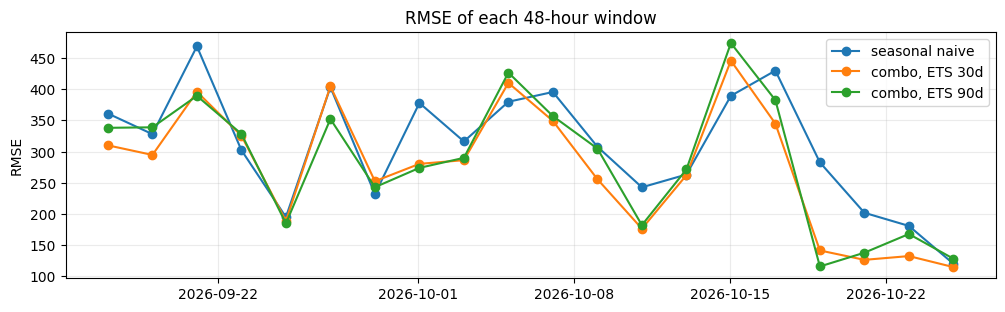

In [85]:
fig, ax = plt.subplots(figsize=(12, 3.2))
dates = [data["ds"].iloc[e] for e in rmse_by_window.index]
for name in ["seasonal naive", "combo, ETS 30d", "combo, ETS 90d"]:
    ax.plot(dates, rmse_by_window[name], marker="o", label=name)
ax.set_title("RMSE of each 48-hour window")
ax.set_ylabel("RMSE")
ax.legend()
plt.show()

I choose 30 days: it gives the lowest RMSE and beats the 90-day version in 14 of 20 windows. Pooled RMSE is 292 versus 322 for seasonal naive, with coverage at 95%.

The longer histories have lower MAPE and slightly better Winkler across all 48 hours, so this is a trade-off rather than a win on every metric.

### Step 6. Results on the last 48 observed hours

This window was already included in validation. Here I inspect its results separately.

In [86]:
last_origin = SCORED[-1]
assert last_origin == len(data) - H
check = pd.DataFrame({
    "seasonal naive": score(y[last_origin:], lookback_predictions["seasonal naive"][last_origin]),
    "30d calibrated combo": score(y[last_origin:], lookback_predictions["combo, ETS 30d"][last_origin]),
}).T[["RMSE", "MAPE", "Winkler", "coverage"]]
display(check)
print(f"RMSE ratio (combo / naive): {check.loc['30d calibrated combo', 'RMSE'] / check.loc['seasonal naive', 'RMSE']:.3f}")

,RMSE,MAPE,Winkler,coverage
seasonal naive,120.404,51.088,568.464,1.0
30d calibrated combo,115.040,39.745,798.045,1.0


RMSE ratio (combo / naive): 0.955


The combination improves RMSE from 120 to 115 and MAPE from 51 to 40. Both intervals cover all observations, but the combination is wider, giving a worse Winkler score (798 vs 568).

## 6. Final model and forecast

The final forecast combines 50% ETS Box–Cox fitted on the latest 30 days and 50% seasonal naive. I use the median-type back-transform without bias adjustment.

I average their 95% bounds, then widen them using errors from the last 12 completed forecasts, separately for day 1 and day 2. Lower bounds are clipped at zero.

The model now forecasts the next 48 unobserved hours.

Mean interval width, before calibration: 739.5
Mean interval width, after calibration : 868.7


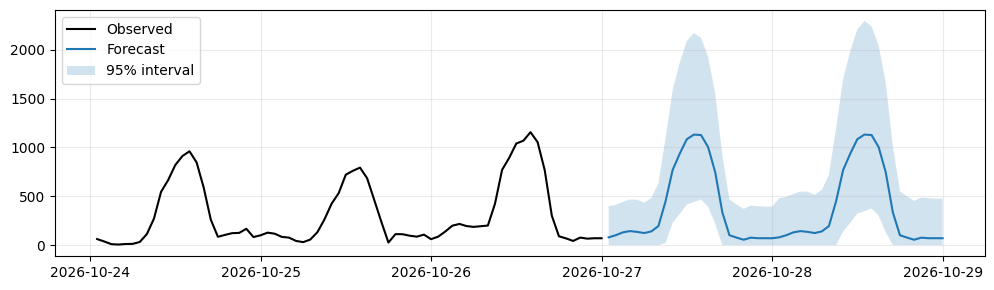

In [87]:
final_ets = ets_at(len(data), 30, False)  # Fit ETS on the latest 30 days.
final_raw = combine(0.5, final_ets, naive_at(len(data)), "avg")

# The 12 most recent completed forecasts (same 30-day combination, uncalibrated).
final_past = {end: raw_by_days[30][end] for end in ORIGINS[-CAL_WINDOW:]}
point, lower, upper = calibrate(final_raw, final_past)

print("Mean interval width, before calibration:", round(np.mean(final_raw[2] - final_raw[1]), 1))
print("Mean interval width, after calibration :", round(np.mean(upper - lower), 1))

fig, ax = plt.subplots(figsize=(12, 3.2))
ax.plot(data["ds"].tail(72), y[-72:], color="black", label="Observed")
ax.plot(FUTURE, point, label="Forecast")
ax.fill_between(FUTURE, lower, upper, alpha=0.2, label="95% interval")
ax.legend()
plt.show()

## 7. Export

The archived first submission stays untouched. This cell writes a reproduced file next to it and compares the two.

In [88]:
submission = pd.DataFrame({"ds": FUTURE, "forecast": point, "lower_95": lower, "upper_95": upper})

# Format and sanity checks required by the task.
assert list(submission.columns) == ["ds", "forecast", "lower_95", "upper_95"]
assert submission.shape == (H, 4)
assert np.isfinite(submission.iloc[:, 1:].to_numpy()).all()
assert (lower >= 0).all() and (lower <= point).all() and (point <= upper).all()

output = Path("submissions")
output.mkdir(exist_ok=True)
submission.to_csv(output / "submission_1_reproduced.csv", index=False)
print("Saved", output / "submission_1_reproduced.csv")

archive = output / "submission_1.csv"
if archive.exists():
    archived = pd.read_csv(archive)
    assert pd.to_datetime(archived["ds"]).equals(FUTURE)
    diff = np.max(np.abs(submission.iloc[:, 1:].to_numpy() - archived.iloc[:, 1:].to_numpy()))
    print("Largest absolute difference from the archived submission:", diff)
else:
    print("No archived submission_1.csv found; skipped the comparison.")
print("Format OK")

Saved submissions/submission_1_reproduced.csv
No archived submission_1.csv found; skipped the comparison.
Format OK
